# E1 Baseline v2 - MobileNetV3-Small

**Project:** Lightweight and Compression-Robust Audio Deepfake Detection for Edge Deployment  
**Experiment:** E1 v2 - 24 kHz clean compact CNN baseline  
**Dataset:** ASVspoof 2019 Logical Access (LA)

This notebook keeps the E1 model scientifically unchanged while updating the input representation to **24 kHz** and using the optimized batched GPU Log-Mel pipeline used by the faster AT-ADD/E2 implementations.

The E1 model remains a scratch-trained **MobileNetV3-Small** classifier. No GRU/LSTM, augmentation, robustness loss, compression, pruning, quantization, or edge benchmarking is included in E1.


# Before running the notebook

Run the ASVspoof manifest preparation before running this notebook if the manifests have not already been created.

The notebook expects the reproducible ASVspoof manifests at:

```text
data/manifests/ASVSpoof/train_manifest.csv
data/manifests/ASVSpoof/dev_manifest.csv
data/manifests/ASVSpoof/eval_manifest.csv
```

The notebook does not recreate the manifests. It reads them exactly as prepared by the project preprocessing pipeline.


# 1. Environment and project paths

This section imports the libraries used by the experiment and defines the paths to the project outputs.

The notebook assumes it is being run from the `notebooks/` directory. Therefore, the project root is resolved as the parent directory of the notebook location.

All experiment outputs are kept separate from the raw dataset so that the original ASVspoof files remain untouched.



In [1]:
# 1. Imports and project paths

from pathlib import Path
import json
import math
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import soundfile as sf
from tqdm.auto import tqdm

from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    accuracy_score
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset,DataLoader
from torchvision.models import mobilenet_v3_small

warnings.filterwarnings("ignore")

# The notebook is stored in project_root/notebooks/
PROJECT_ROOT=Path("..").resolve()

DATA_ROOT=PROJECT_ROOT/"data"
MANIFEST_DIR=DATA_ROOT/"manifests"/"ASVSpoof"

TRAIN_MANIFEST=MANIFEST_DIR/"train_manifest.csv"
DEV_MANIFEST=MANIFEST_DIR/"dev_manifest.csv"
EVAL_MANIFEST=MANIFEST_DIR/"eval_manifest.csv"

# E1 v2 has its own experiment directories so it cannot overwrite E1 v1 or E2.
CHECKPOINT_DIR=PROJECT_ROOT/"checkpoints"/"ASV_E1_v2"
EXPERIMENT_DIR=PROJECT_ROOT/"experiments"/"baselines"/"ASV_E1_v2"
RESULT_TABLE_DIR=PROJECT_ROOT/"results"/"tables"/"ASV_E1_v2"
RESULT_FIGURE_DIR=PROJECT_ROOT/"results"/"figures"/"ASV_E1_v2"
RESULT_LOG_DIR=PROJECT_ROOT/"results"/"logs"/"ASV_E1_v2"

for directory in [
    CHECKPOINT_DIR,
    EXPERIMENT_DIR,
    RESULT_TABLE_DIR,
    RESULT_FIGURE_DIR,
    RESULT_LOG_DIR
]:
    directory.mkdir(parents=True,exist_ok=True)

print("Project root:",PROJECT_ROOT)
print("Manifest directory:",MANIFEST_DIR)
print("Checkpoint directory:",CHECKPOINT_DIR)
print("Experiment directory:",EXPERIMENT_DIR)
print("Figure directory:",RESULT_FIGURE_DIR)


Project root: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification
Manifest directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/ASVSpoof
Checkpoint directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/checkpoints/ASV_E1_v2
Experiment directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/ASV_E1_v2
Figure directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/ASV_E1_v2


# 2. Verify the prepared dataset

The preprocessing script creates three reproducible manifests:

- `train_manifest.csv`
- `dev_manifest.csv`
- `eval_manifest.csv`

We first check that these files exist before loading any data.

If the train or development manifest is missing, the notebook stops rather than silently creating a new split.


In [2]:
# 2. Check the generated manifests before training

required_files=[
    TRAIN_MANIFEST,
    DEV_MANIFEST,
    EVAL_MANIFEST
]

for path in required_files:
    status="OK" if path.exists() else "MISSING"
    print(f"{status:<8} {path}")

if not TRAIN_MANIFEST.exists() or not DEV_MANIFEST.exists():
    raise FileNotFoundError(
        "Train/dev manifests were not found. "
        "Run prepare_asvspoof_v1.py first."
    )


OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/ASVSpoof/train_manifest.csv
OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/ASVSpoof/dev_manifest.csv
OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/ASVSpoof/eval_manifest.csv


# 3. Reproducibility and experiment configuration

E1 needs a fixed configuration so that later experiments can be compared fairly.

The important settings recorded here include:

- random seed
- audio sampling rate
- segment duration
- STFT parameters
- number of Mel bins
- batch size
- learning rate
- optimizer settings
- experiment version
- input preprocessing version

For the final E1 experiment, the fraction variables remain `None`, meaning the complete prepared partitions are used.
**Deterministic cuDNN settings used when CUDA is available:**

```python
torch.backends.cudnn.deterministic=True
torch.backends.cudnn.benchmark=False
```

The notebook does not enable `torch.use_deterministic_algorithms(...)`.


In [3]:
# 3. Reproducibility and training configuration

SEED=42

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def seed_worker(worker_id):
    worker_seed=torch.initial_seed()%2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

seed_everything(SEED)

DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")

if DEVICE.type=="cuda":
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.benchmark=False
    print("Device:",torch.cuda.get_device_name(0))
    print("cuDNN deterministic:",torch.backends.cudnn.deterministic)
    print("cuDNN benchmark:",torch.backends.cudnn.benchmark)
else:
    print("Device: CPU")

# Experiment versions
EXPERIMENT_VERSION="v2.0"
INPUT_PREPROCESSING_VERSION="v2.0"

# Training configuration
BATCH_SIZE=32
EPOCHS=20
LEARNING_RATE=1e-3
WEIGHT_DECAY=1e-4
PATIENCE=5

# Optimized input pipeline
NUM_WORKERS=4
PREFETCH_FACTOR=2

# Audio configuration: E1 v2 uses the higher 24 kHz frontend
SAMPLE_RATE=24000
SEGMENT_SECONDS=4
NUM_SAMPLES=SAMPLE_RATE*SEGMENT_SECONDS

N_FFT=1024
WIN_LENGTH=600
HOP_LENGTH=240
N_MELS=80

LOG_EPS=1e-10

# Keep these as None for the final experiment
TRAIN_FRACTION=None
DEV_FRACTION=None
EVAL_FRACTION=None
STATS_MAX_FILES=None

print("Experiment version:",EXPERIMENT_VERSION)
print("Input preprocessing version:",INPUT_PREPROCESSING_VERSION)
print("Seed:",SEED)
print("Sample rate:",SAMPLE_RATE)
print("Segment seconds:",SEGMENT_SECONDS)
print("N_FFT:",N_FFT)
print("Win length:",WIN_LENGTH)
print("Hop length:",HOP_LENGTH)
print("Mel bins:",N_MELS)
print("Batch size:",BATCH_SIZE)
print("Epochs:",EPOCHS)
print("DataLoader workers:",NUM_WORKERS)
print("Prefetch factor:",PREFETCH_FACTOR)
print("Device:",DEVICE)


Device: NVIDIA GeForce RTX 3060 Laptop GPU
cuDNN deterministic: True
cuDNN benchmark: False
Experiment version: v2.0
Input preprocessing version: v2.0
Seed: 42
Sample rate: 24000
Segment seconds: 4
N_FFT: 1024
Win length: 600
Hop length: 240
Mel bins: 80
Batch size: 32
Epochs: 20
DataLoader workers: 4
Prefetch factor: 2
Device: cuda


# 4. Load the reproducible manifests

The manifests contain the file paths and labels prepared by `prepare_asvspoof_v1.py`.

We use the official ASVspoof train/dev/eval partitions rather than creating a random split inside the model notebook.

This is important because changing the split here would make E1 difficult to compare with later baseline experiments.


In [4]:
# 4. Load the reproducible manifests

train_df=pd.read_csv(TRAIN_MANIFEST)
dev_df=pd.read_csv(DEV_MANIFEST)

if EVAL_MANIFEST.exists():
    eval_df=pd.read_csv(EVAL_MANIFEST)
else:
    eval_df=pd.DataFrame()

print("Train:",len(train_df))
print("Dev:",len(dev_df))
print("Eval:",len(eval_df))
print("\nTrain columns:")
print(train_df.columns.tolist())
print("\nFirst training entries:")
display(train_df.head())


Train: 25380
Dev: 24844
Eval: 71237

Train columns:
['file_id', 'audio_path', 'speaker_id', 'system_id', 'key', 'label', 'split']

First training entries:


,file_id,audio_path,speaker_id,system_id,key,label,split
0,LA_T_1138215,data/raw/ASVspoof2019_LA/ASVspoof2019_LA_train...,LA_0079,-,bonafide,0,train
1,LA_T_1271820,data/raw/ASVspoof2019_LA/ASVspoof2019_LA_train...,LA_0079,-,bonafide,0,train
2,LA_T_1272637,data/raw/ASVspoof2019_LA/ASVspoof2019_LA_train...,LA_0079,-,bonafide,0,train
3,LA_T_1276960,data/raw/ASVspoof2019_LA/ASVspoof2019_LA_train...,LA_0079,-,bonafide,0,train
4,LA_T_1341447,data/raw/ASVspoof2019_LA/ASVspoof2019_LA_train...,LA_0079,-,bonafide,0,train


## Dataset integrity checks

Before training, we check whether the paths recorded in the manifests actually point to audio files.

A missing file should be investigated before the final experiment rather than silently skipped.


In [5]:
# 5. Verify that manifest paths point to existing files

def check_audio_files(df,project_root):
    if len(df)==0:
        return 0

    return sum(
        not (project_root/Path(path)).exists()
        for path in df["audio_path"]
    )

for name,df in [
    ("train",train_df),
    ("dev",dev_df),
    ("eval",eval_df)
]:
    if len(df)==0:
        continue

    missing=check_audio_files(df,PROJECT_ROOT)
    print(f"{name:<8}: {missing} missing audio files")

    if missing>0:
        print(f"WARNING: {name} contains missing files.")


train   : 0 missing audio files
dev     : 0 missing audio files
eval    : 0 missing audio files


## Class and speaker distribution

The class distribution is inspected before training because ASVspoof contains both bonafide and spoofed examples and the distribution is not necessarily balanced.

We also inspect speaker IDs. This is an audit only; the notebook does not modify the official partitions.


In [6]:
# 6. Inspect class and identity information from the manifests

def show_split_summary(df,name):
    print(f"\n{name.upper()}")
    print("-"*50)
    print("Files:",len(df))

    if "key" in df.columns:
        print("\nClass counts:")
        print(df["key"].value_counts(dropna=False))

    if "speaker_id" in df.columns:
        print("Speakers:",df["speaker_id"].nunique())

    if "system_id" in df.columns:
        print("System IDs:",df["system_id"].nunique())

show_split_summary(train_df,"train")
show_split_summary(dev_df,"dev")

if len(eval_df):
    show_split_summary(eval_df,"eval")

train_speakers=set(train_df["speaker_id"])
dev_speakers=set(dev_df["speaker_id"])

print("\nTrain/dev speaker overlap:",len(train_speakers&dev_speakers))



TRAIN
--------------------------------------------------
Files: 25380

Class counts:
key
spoof       22800
bonafide     2580
Name: count, dtype: int64
Speakers: 20
System IDs: 7

DEV
--------------------------------------------------
Files: 24844

Class counts:
key
spoof       22296
bonafide     2548
Name: count, dtype: int64
Speakers: 20
System IDs: 7

EVAL
--------------------------------------------------
Files: 71237

Class counts:
key
spoof       63882
bonafide     7355
Name: count, dtype: int64
Speakers: 67
System IDs: 14

Train/dev speaker overlap: 0


# 5. E1 input preprocessing

The dataset preparation script handles dataset organization and reproducible manifests. The transformations below are **model-input preprocessing** and are performed when an audio file is loaded.

### Pipeline

```text
FLAC
  ↓
Mono
  ↓
24 kHz
  ↓
4-second crop / zero-padding
  ↓
STFT
  ↓
80-bin Mel spectrogram
  ↓
Log compression
  ↓
Training-set normalization
  ↓
1-channel tensor
  ↓
MobileNetV3-Small
```

### Audio representation

For E1 we use:

| Setting | Value |
|---|---:|
| Sampling rate | 24 kHz |
| Segment length | 4 seconds |
| FFT size | 1024 |
| Window length | 400 samples |
| Hop length | 160 samples |
| Window | Hann |
| Mel bins | 80 |
| Spectrogram power | 2 |
| Input channels | 1 |

A 400-sample window at 16 kHz corresponds to 25 ms, while the 160-sample hop corresponds to 10 ms.

### Training vs evaluation

For recordings longer than four seconds:

- **Training:** random 4-second crop
- **Validation/evaluation:** center 4-second crop

For recordings shorter than four seconds, zero-padding is used.

No environmental noise, codec degradation, SpecAugment, or robustness transformation is applied in E1.


In [7]:
# 7. Audio loading and batched GPU Log-Mel conversion

# CPU-side work is limited to audio decoding, mono conversion, resampling and cropping.
# The expensive STFT/Mel/log operation is performed after batching on the GPU.

def load_audio(path,target_sr=SAMPLE_RATE):
    waveform,sr=sf.read(path,dtype="float32")

    if waveform.ndim>1:
        waveform=waveform.mean(axis=1)

    if sr!=target_sr:
        waveform=librosa.resample(
            waveform,
            orig_sr=sr,
            target_sr=target_sr
        )

    waveform=waveform.astype(np.float32)
    waveform=np.nan_to_num(
        waveform,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    return waveform


def fixed_length_audio(waveform,training=False):
    if len(waveform)>=NUM_SAMPLES:
        if training:
            start=np.random.randint(
                0,
                len(waveform)-NUM_SAMPLES+1
            )
        else:
            start=(len(waveform)-NUM_SAMPLES)//2

        waveform=waveform[
            start:start+NUM_SAMPLES
        ]

    else:
        padded=np.zeros(
            NUM_SAMPLES,
            dtype=np.float32
        )
        padded[:len(waveform)]=waveform
        waveform=padded

    return waveform


class GPULogMel(nn.Module):

    def __init__(
        self,
        sample_rate,
        n_fft,
        win_length,
        hop_length,
        n_mels,
        log_eps=1e-10
    ):
        super().__init__()

        self.n_fft=n_fft
        self.win_length=win_length
        self.hop_length=hop_length
        self.log_eps=log_eps

        window=torch.hann_window(
            win_length,
            periodic=True,
            dtype=torch.float32
        )

        mel_filter=librosa.filters.mel(
            sr=sample_rate,
            n_fft=n_fft,
            n_mels=n_mels,
            fmin=0.0,
            fmax=sample_rate/2.0,
            htk=False,
            norm="slaney"
        )

        self.register_buffer(
            "window",
            window
        )
        self.register_buffer(
            "mel_filter",
            torch.tensor(
                mel_filter,
                dtype=torch.float32
            )
        )

    def forward(self,waveforms):
        stft=torch.stft(
            waveforms.float(),
            n_fft=self.n_fft,
            hop_length=self.hop_length,
            win_length=self.win_length,
            window=self.window,
            center=True,
            pad_mode="constant",
            return_complex=True
        )

        power=stft.abs().pow(2.0)

        mel=torch.matmul(
            self.mel_filter,
            power
        )

        log_mel=torch.log(
            torch.clamp(
                mel,
                min=self.log_eps
            )
        )

        return log_mel


gpu_logmel=GPULogMel(
    SAMPLE_RATE,
    N_FFT,
    WIN_LENGTH,
    HOP_LENGTH,
    N_MELS,
    LOG_EPS
).to(DEVICE)


def cpu_logmel_for_visualization(waveform):
    mel=librosa.feature.melspectrogram(
        y=waveform,
        sr=SAMPLE_RATE,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        win_length=WIN_LENGTH,
        window="hann",
        n_mels=N_MELS,
        power=2.0
    )

    return np.log(
        np.maximum(mel,LOG_EPS)
    ).astype(np.float32)


## Visual sanity check

Before training, we display one example log-Mel spectrogram.

This is mainly a pipeline check: we want to confirm that audio loading, resampling, cropping and Mel extraction are producing a valid two-dimensional time-frequency representation.


Waveform shape: (96000,)
Log-Mel shape: (80, 401)


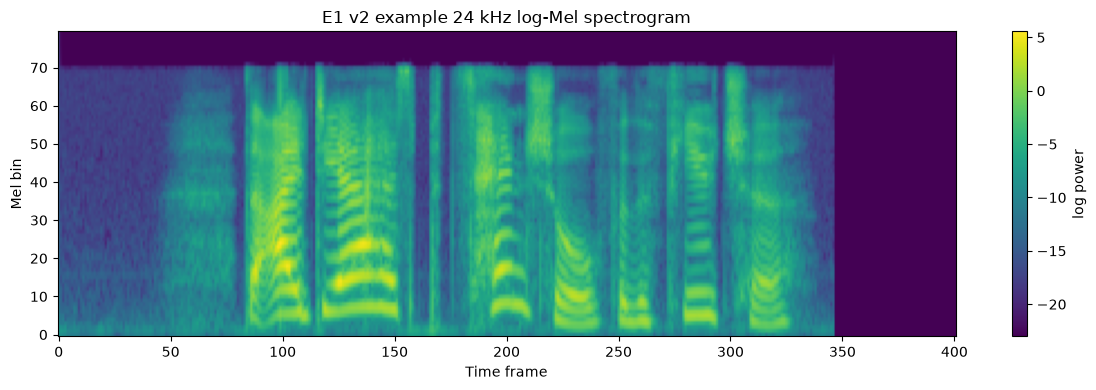

In [8]:
# 8. Visual sanity check for the 24 kHz input representation

sample_path=PROJECT_ROOT/Path(
    train_df.iloc[0]["audio_path"]
)

sample_wave=load_audio(sample_path)
sample_wave=fixed_length_audio(
    sample_wave,
    training=False
)

sample_logmel=cpu_logmel_for_visualization(sample_wave)

print("Waveform shape:",sample_wave.shape)
print("Log-Mel shape:",sample_logmel.shape)

plt.figure(figsize=(12,4))
plt.imshow(
    sample_logmel,
    origin="lower",
    aspect="auto"
)
plt.title("E1 v2 example 24 kHz log-Mel spectrogram")
plt.xlabel("Time frame")
plt.ylabel("Mel bin")
plt.colorbar(label="log power")
plt.tight_layout()
plt.show()


# 6. Optional smoke-test subsets

The following settings allow a small subset of the data to be used while debugging the pipeline.

For example:

```python
TRAIN_FRACTION=0.02
DEV_FRACTION=0.02
```

can be used to verify that the complete training loop works.

For the **actual E1 experiment**, keep all three fraction variables as `None`.

This prevents a debugging run from accidentally being treated as the final baseline.


In [9]:
# 9. Optional smoke-test subsets
# Keep these as None for the final experiment (In code cell 3)

def take_fraction(df,fraction,seed=42):
    if fraction is None or fraction>=1.0:
        return df.copy()

    if fraction<=0:
        raise ValueError("Fraction must be greater than 0.")

    pieces=[]

    for label,group in df.groupby("label"):
        n=max(1,int(len(group)*fraction))
        pieces.append(group.sample(n=n,random_state=seed))

    return pd.concat(pieces).sample(
        frac=1.0,
        random_state=seed
    ).reset_index(drop=True)


train_run_df=take_fraction(train_df,TRAIN_FRACTION,SEED)
dev_run_df=take_fraction(dev_df,DEV_FRACTION,SEED)

if len(eval_df):
    eval_run_df=take_fraction(eval_df,EVAL_FRACTION,SEED)
else:
    eval_run_df=eval_df

print("Train:",len(train_run_df))
print("Dev:",len(dev_run_df))
print("Eval:",len(eval_run_df))


Train: 25380
Dev: 24844
Eval: 71237


# 7. Training-set normalization statistics

The mean and standard deviation of the log-Mel representation are calculated using **only the training partition**.

Validation and evaluation data are not used to calculate these statistics.

Once calculated, the values are saved to:

```text
experiments/baselines/ASV_E1_v2/logmel_stats.json
```

Future E1 runs can reuse the saved statistics instead of recalculating them, provided the preprocessing version and dataset preparation remain unchanged.


In [10]:
# 10. Calculate or load normalization statistics using only the training set

class StatsWaveformDataset(Dataset):

    def __init__(self,df):
        self.df=df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self,index):
        path=PROJECT_ROOT/Path(
            self.df.iloc[index]["audio_path"]
        )
        waveform=load_audio(path)
        waveform=fixed_length_audio(
            waveform,
            training=False
        )
        return torch.from_numpy(waveform).float()


def compute_logmel_stats(df,max_files=None):
    work_df=df

    if max_files is not None and max_files<len(df):
        work_df=df.sample(
            n=max_files,
            random_state=SEED
        )

    stats_dataset=StatsWaveformDataset(work_df)

    loader_kwargs={
        "batch_size":BATCH_SIZE,
        "shuffle":False,
        "num_workers":NUM_WORKERS,
        "pin_memory":DEVICE.type=="cuda",
        "persistent_workers":NUM_WORKERS>0,
        "worker_init_fn":seed_worker,
        "generator":torch.Generator().manual_seed(SEED)
    }

    if NUM_WORKERS>0:
        loader_kwargs["prefetch_factor"]=PREFETCH_FACTOR

    stats_loader=DataLoader(
        stats_dataset,
        **loader_kwargs
    )

    total_sum=0.0
    total_sq_sum=0.0
    total_count=0

    gpu_logmel.eval()

    with torch.no_grad():
        for waveforms in tqdm(
            stats_loader,
            desc="Computing training log-Mel statistics"
        ):
            waveforms=waveforms.to(
                DEVICE,
                non_blocking=True
            )

            log_mel=gpu_logmel(waveforms)

            total_sum+=float(log_mel.sum().item())
            total_sq_sum+=float(
                log_mel.pow(2).sum().item()
            )
            total_count+=log_mel.numel()

    mean=total_sum/total_count
    variance=max(
        total_sq_sum/total_count-mean**2,
        1e-8
    )
    std=math.sqrt(variance)

    return float(mean),float(std)


stats_path=EXPERIMENT_DIR/"logmel_stats.json"

if stats_path.exists() and STATS_MAX_FILES is None:
    with stats_path.open("r",encoding="utf-8") as f:
        stats=json.load(f)

    compatible=(
        stats.get("version")==INPUT_PREPROCESSING_VERSION
        and stats.get("sample_rate")==SAMPLE_RATE
        and stats.get("segment_seconds")==SEGMENT_SECONDS
        and stats.get("n_fft")==N_FFT
        and stats.get("win_length")==WIN_LENGTH
        and stats.get("hop_length")==HOP_LENGTH
        and stats.get("n_mels")==N_MELS
        and stats.get("log_eps")==LOG_EPS
    )

    if not compatible:
        print("Cached statistics are incompatible; recomputing.")
        stats=None
    else:
        MEL_MEAN=float(stats["mean"])
        MEL_STD=float(stats["std"])
        print("Loaded compatible cached training statistics.")
else:
    stats=None

if stats is None:
    MEL_MEAN,MEL_STD=compute_logmel_stats(
        train_run_df,
        STATS_MAX_FILES
    )

    stats={
        "version":INPUT_PREPROCESSING_VERSION,
        "mean":MEL_MEAN,
        "std":MEL_STD,
        "seed":SEED,
        "sample_rate":SAMPLE_RATE,
        "segment_seconds":SEGMENT_SECONDS,
        "n_fft":N_FFT,
        "win_length":WIN_LENGTH,
        "hop_length":HOP_LENGTH,
        "n_mels":N_MELS,
        "log_eps":LOG_EPS
    }

    with stats_path.open("w",encoding="utf-8") as f:
        json.dump(stats,f,indent=2)

print("Mel mean:",MEL_MEAN)
print("Mel std :",MEL_STD)


Loaded compatible cached training statistics.
Mel mean: -13.281197994965305
Mel std : 7.909739538902643


# 8. PyTorch dataset and dataloaders

The `ASVspoofDataset` class connects the manifests to the preprocessing pipeline.

Each item returned by the dataset contains:

```text
log-Mel spectrogram → input tensor
class label          → target
file ID               → used for prediction tracking
```

The training dataset enables random cropping, while the development dataset uses deterministic center cropping.


In [11]:
# 11. PyTorch waveform dataset and optimized DataLoaders

class ASVspoofWaveformDataset(Dataset):

    def __init__(self,df,training):
        self.df=df.reset_index(drop=True)
        self.training=training

    def __len__(self):
        return len(self.df)

    def __getitem__(self,index):
        row=self.df.iloc[index]

        audio_path=PROJECT_ROOT/Path(
            row["audio_path"]
        )

        waveform=load_audio(audio_path)
        waveform=fixed_length_audio(
            waveform,
            self.training
        )

        y=torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return (
            torch.from_numpy(waveform).float(),
            y,
            row["file_id"]
        )


train_dataset=ASVspoofWaveformDataset(
    train_run_df,
    True
)

dev_dataset=ASVspoofWaveformDataset(
    dev_run_df,
    False
)

loader_kwargs={
    "batch_size":BATCH_SIZE,
    "num_workers":NUM_WORKERS,
    "pin_memory":DEVICE.type=="cuda",
    "persistent_workers":NUM_WORKERS>0,
    "worker_init_fn":seed_worker,
    "generator":torch.Generator().manual_seed(SEED)
}

if NUM_WORKERS>0:
    loader_kwargs["prefetch_factor"]=PREFETCH_FACTOR

train_loader=DataLoader(
    train_dataset,
    shuffle=True,
    **loader_kwargs
)

dev_loader=DataLoader(
    dev_dataset,
    shuffle=False,
    **loader_kwargs
)

print("Dataset returns waveform batches; Log-Mel extraction is batched on",DEVICE)
waveform,y,file_id=train_dataset[0]
print("Waveform shape:",waveform.shape)
print("Label:",y.item())
print("File:",file_id)


Dataset returns waveform batches; Log-Mel extraction is batched on cuda
Waveform shape: torch.Size([96000])
Label: 0
File: LA_T_1138215


# 9. E1 model - MobileNetV3-Small

MobileNetV3-Small is our first compact CNN baseline.

The purpose of E1 is to establish a clean, lightweight reference before we move to more complex models and robustness experiments.

The model is trained **from scratch** using `weights=None`. This keeps the baseline configuration explicit and avoids mixing ImageNet pretraining into the first compact baseline.

Because a log-Mel spectrogram has one channel rather than three RGB channels, the first convolution is changed from 3 input channels to 1.


In [12]:
# 12. Build MobileNetV3-Small for one-channel spectrogram input

class MobileNetV3SmallAudio(nn.Module):
    def __init__(self,num_classes=2):
        super().__init__()

        self.backbone=mobilenet_v3_small(
            weights=None,
            num_classes=num_classes
        )

        # Replace the RGB input layer with a single-channel input layer
        old_conv=self.backbone.features[0][0]

        new_conv=nn.Conv2d(
            in_channels=1,
            out_channels=old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            dilation=old_conv.dilation,
            groups=old_conv.groups,
            bias=False
        )

        self.backbone.features[0][0]=new_conv

    def forward(self,x):
        return self.backbone(x)


model=MobileNetV3SmallAudio(num_classes=2).to(DEVICE)

total_params=sum(p.numel() for p in model.parameters())
trainable_params=sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Total parameters: 1,519,618
Trainable parameters: 1,519,618


# 10. Loss function, optimizer and scheduler

The training labels are slightly imbalanced, so E1 uses class-weighted cross entropy.

The optimizer is AdamW with the configured learning rate and weight decay.

A `ReduceLROnPlateau` scheduler monitors development Macro-F1 and reduces the learning rate when that metric plateaus.

The development set is used for model selection; the evaluation set is not used to choose the model.


The executable cell below defines `criterion`, `optimizer` and `scheduler` before the training function is called.


In [13]:
# 10. Loss function, optimizer and scheduler

# Class-weighted cross entropy compensates for the class imbalance
# in the training partition without changing the dataset itself.
class_counts=(
    train_run_df["label"]
    .value_counts()
    .reindex([0,1],fill_value=0)
    .to_numpy(dtype=np.float64)
)

if np.any(class_counts==0):
    raise ValueError(
        "Both bonafide (0) and spoof (1) classes must be present "
        "in the training partition."
    )

class_weights=class_counts.sum()/(2.0*class_counts)

class_weights=torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE
)

criterion=nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer=torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

print("Class counts [bonafide, spoof]:",class_counts.astype(int))
print(
    "Class weights [bonafide, spoof]:",
    class_weights.detach().cpu().numpy()
)
print("Optimizer:",optimizer.__class__.__name__)
print("Learning rate:",LEARNING_RATE)
print("Weight decay:",WEIGHT_DECAY)
print("Scheduler:",scheduler.__class__.__name__)


Class counts [bonafide, spoof]: [ 2580 22800]
Class weights [bonafide, spoof]: [4.918605   0.55657893]
Optimizer: AdamW
Learning rate: 0.001
Weight decay: 0.0001
Scheduler: ReduceLROnPlateau


In [14]:
# 11. Batched waveform -> normalized Log-Mel tensor

def waveform_batch_to_features(waveforms):
    waveforms=waveforms.to(
        DEVICE,
        non_blocking=True
    )

    log_mel=gpu_logmel(waveforms)

    log_mel=(
        log_mel-MEL_MEAN
    )/MEL_STD

    return log_mel.unsqueeze(1)


# 12. Evaluation metrics

The main E1 metrics are:

### Macro-F1

Macro-F1 calculates F1 separately for bonafide and spoof classes and then averages them. This prevents the larger class from dominating the summary score.

### AUROC

AUROC measures how well the model ranks spoofed and bonafide examples across decision thresholds.

### EER

Equal Error Rate is calculated from the ROC curve by finding the point where false-positive and false-negative rates are approximately equal.

Accuracy is also recorded, but it is not the primary metric for comparing the detector.


In [15]:
# 14. Evaluation metrics

def compute_eer(y_true,scores):
    y_true=np.asarray(y_true)
    scores=np.asarray(scores)

    if len(np.unique(y_true))<2:
        return float("nan"),float("nan")

    fpr,tpr,thresholds=roc_curve(y_true,scores)
    fnr=1.0-tpr
    index=np.nanargmin(np.abs(fpr-fnr))
    eer=float((fpr[index]+fnr[index])/2.0)
    threshold=float(thresholds[index])

    return eer,threshold


def calculate_metrics(y_true,scores,threshold=0.5):
    y_true=np.asarray(y_true).astype(int)
    scores=np.asarray(scores).astype(float)
    predictions=(scores>=threshold).astype(int)

    metrics={
        "macro_f1":float(
            f1_score(
                y_true,
                predictions,
                average="macro",
                zero_division=0
            )
        ),
        "accuracy":float(
            accuracy_score(y_true,predictions)
        ),
        "auroc":float("nan")
    }

    if len(np.unique(y_true))==2:
        metrics["auroc"]=float(
            roc_auc_score(y_true,scores)
        )

    eer,eer_threshold=compute_eer(
        y_true,
        scores
    )

    metrics["eer"]=eer
    metrics["eer_threshold"]=eer_threshold

    return metrics,predictions


@torch.no_grad()
def run_evaluation(model,loader,criterion=None):
    model.eval()

    total_loss=0.0
    total_items=0
    all_labels=[]
    all_scores=[]
    all_file_ids=[]

    for waveforms,y,file_ids in tqdm(
        loader,
        desc="Evaluating",
        leave=False
    ):
        x=waveform_batch_to_features(
            waveforms
        )

        y=y.to(
            DEVICE,
            non_blocking=True
        )

        logits=model(x)

        if criterion is not None:
            loss=criterion(logits,y)
            total_loss+=float(loss.item())*x.size(0)

        scores=torch.softmax(
            logits,
            dim=1
        )[:,1]

        all_labels.extend(
            y.cpu().numpy().tolist()
        )
        all_scores.extend(
            scores.cpu().numpy().tolist()
        )
        all_file_ids.extend(
            list(file_ids)
        )

        total_items+=x.size(0)

    avg_loss=total_loss/max(total_items,1)

    metrics,predictions=calculate_metrics(
        all_labels,
        all_scores
    )

    metrics["loss"]=avg_loss

    return (
        metrics,
        np.asarray(all_labels),
        np.asarray(all_scores),
        predictions,
        all_file_ids
    )


## GPU training

When CUDA is available, mixed-precision training is enabled to reduce GPU memory usage and improve training speed.

On CPU, the same notebook automatically falls back to normal floating-point training.


In [16]:
# 15. Mixed-precision training setup

amp_enabled=DEVICE.type=="cuda"
scaler=torch.amp.GradScaler("cuda",enabled=amp_enabled)

def autocast_context():
    return torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=amp_enabled
    )

# 13. Training loop

The model is trained on the training partition and evaluated on the development partition after every epoch.

The best checkpoint is selected using **development Macro-F1**.

Early stopping is used when development Macro-F1 does not improve for the configured patience period.

The evaluation partition is not used during model selection.


In [17]:
# 16. Train one epoch

def train_one_epoch(model,loader):
    model.train()

    running_loss=0.0
    total_items=0
    total_correct=0

    progress=tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for waveforms,y,_ in progress:
        x=waveform_batch_to_features(
            waveforms
        )

        y=y.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            logits=model(x)
            loss=criterion(logits,y)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        predictions=logits.argmax(dim=1)
        total_correct+=int(
            (predictions==y).sum().item()
        )

        running_loss+=float(loss.item())*x.size(0)
        total_items+=x.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{total_correct/max(total_items,1):.4f}"
        )

    train_loss=running_loss/max(total_items,1)
    train_accuracy=total_correct/max(total_items,1)

    return train_loss,train_accuracy


In [18]:
# 17. Train E1 v2 and save the best validation checkpoint

history=[]

best_val_f1=-np.inf
best_epoch=-1
epochs_without_improvement=0

best_checkpoint_path=(
    CHECKPOINT_DIR
    /"E1_MobileNetV3Small_v2_best.pt"
)

for epoch in range(1,EPOCHS+1):
    start_time=time.time()

    train_loss,train_accuracy=train_one_epoch(
        model,
        train_loader
    )

    val_metrics,val_y,val_scores,val_preds,val_ids=run_evaluation(
        model,
        dev_loader,
        criterion
    )

    scheduler.step(
        val_metrics["macro_f1"]
    )

    epoch_time=time.time()-start_time

    row={
        "epoch":epoch,
        "train_loss":train_loss,
        "train_accuracy":train_accuracy,
        "val_loss":val_metrics["loss"],
        "val_accuracy":val_metrics["accuracy"],
        "val_macro_f1":val_metrics["macro_f1"],
        "val_auroc":val_metrics["auroc"],
        "val_eer":val_metrics["eer"],
        "lr":optimizer.param_groups[0]["lr"],
        "epoch_seconds":epoch_time
    }

    history.append(row)

    print(
        f"Epoch {epoch:02d} | "
        f"train loss {train_loss:.4f} | "
        f"train acc {train_accuracy:.4f} | "
        f"val loss {val_metrics['loss']:.4f} | "
        f"val acc {val_metrics['accuracy']:.4f} | "
        f"val F1 {val_metrics['macro_f1']:.4f} | "
        f"val AUROC {val_metrics['auroc']:.4f} | "
        f"val EER {val_metrics['eer']:.4f} | "
        f"time {epoch_time:.1f}s"
    )

    if val_metrics["macro_f1"]>best_val_f1:
        best_val_f1=val_metrics["macro_f1"]
        best_epoch=epoch
        epochs_without_improvement=0

        torch.save(
            {
                "experiment":"E1",
                "experiment_version":EXPERIMENT_VERSION,
                "input_preprocessing_version":INPUT_PREPROCESSING_VERSION,
                "model_name":"MobileNetV3-Small",
                "epoch":epoch,
                "model_state_dict":model.state_dict(),
                "optimizer_state_dict":optimizer.state_dict(),
                "scheduler_state_dict":scheduler.state_dict(),
                "best_val_macro_f1":best_val_f1,
                "config":{
                    "seed":SEED,
                    "sample_rate":SAMPLE_RATE,
                    "segment_seconds":SEGMENT_SECONDS,
                    "n_fft":N_FFT,
                    "win_length":WIN_LENGTH,
                    "hop_length":HOP_LENGTH,
                    "n_mels":N_MELS,
                    "batch_size":BATCH_SIZE,
                    "learning_rate":LEARNING_RATE,
                    "weight_decay":WEIGHT_DECAY,
                    "mel_mean":MEL_MEAN,
                    "mel_std":MEL_STD,
                    "num_workers":NUM_WORKERS,
                    "prefetch_factor":PREFETCH_FACTOR
                }
            },
            best_checkpoint_path
        )

        print("  -> saved new best checkpoint")

    else:
        epochs_without_improvement+=1

    if epochs_without_improvement>=PATIENCE:
        print(
            f"Early stopping at epoch {epoch}."
        )
        break

history_df=pd.DataFrame(history)

history_path=EXPERIMENT_DIR/"training_history.csv"
history_df.to_csv(
    history_path,
    index=False
)

print()
print("Best validation Macro-F1:",best_val_f1)
print("Best epoch:",best_epoch)
print("Checkpoint:",best_checkpoint_path)


Training:   0%|          | 0/794 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/777 [00:00<?, ?it/s]

Epoch 01 | train loss 0.1234 | train acc 0.9546 | val loss 0.2956 | val acc 0.9627 | val F1 0.8804 | val AUROC 0.9315 | val EER 0.1553 | time 68.0s
  -> saved new best checkpoint


Training:   0%|          | 0/794 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/777 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/777 [00:00<?, ?it/s]

Epoch 18 | train loss 0.0007 | train acc 0.9997 | val loss 0.0011 | val acc 0.9996 | val F1 0.9989 | val AUROC 1.0000 | val EER 0.0004 | time 55.0s


Training:   0%|          | 0/794 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/777 [00:00<?, ?it/s]

Epoch 19 | train loss 0.0009 | train acc 0.9997 | val loss 0.0011 | val acc 0.9996 | val F1 0.9990 | val AUROC 1.0000 | val EER 0.0007 | time 57.9s
Early stopping at epoch 19.

Best validation Macro-F1: 0.99912567236768
Best epoch: 14
Checkpoint: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/checkpoints/ASV_E1_v2/E1_MobileNetV3Small_v2_best.pt


## Training curves

The training curves provide a quick way to identify:

- underfitting
- overfitting
- unstable optimization
- whether the development performance has stopped improving

These plots are saved under `results/figures/` for the project record.


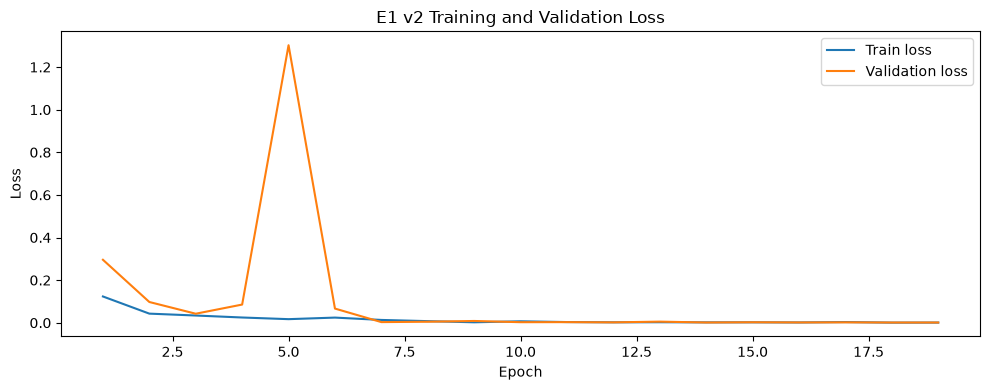

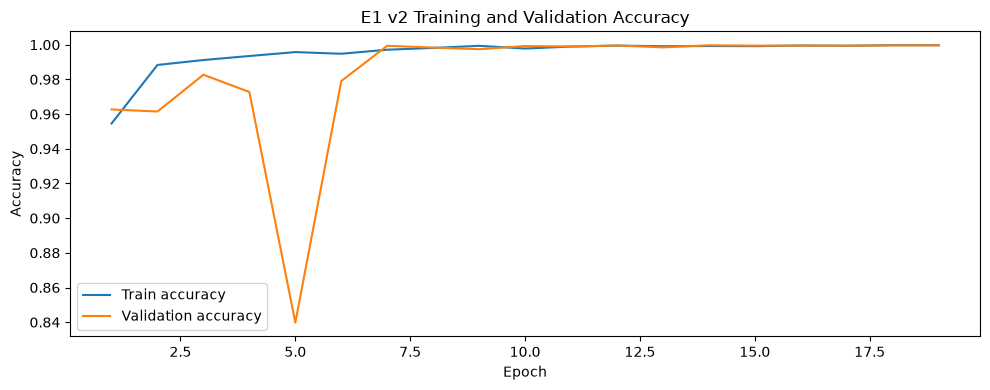

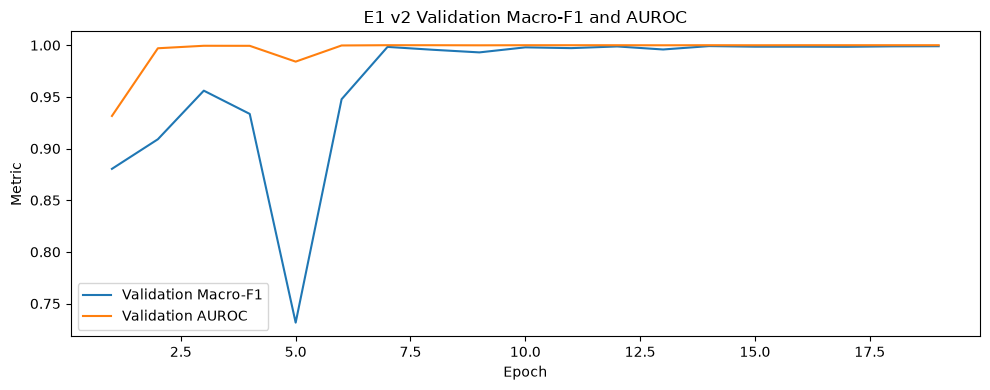

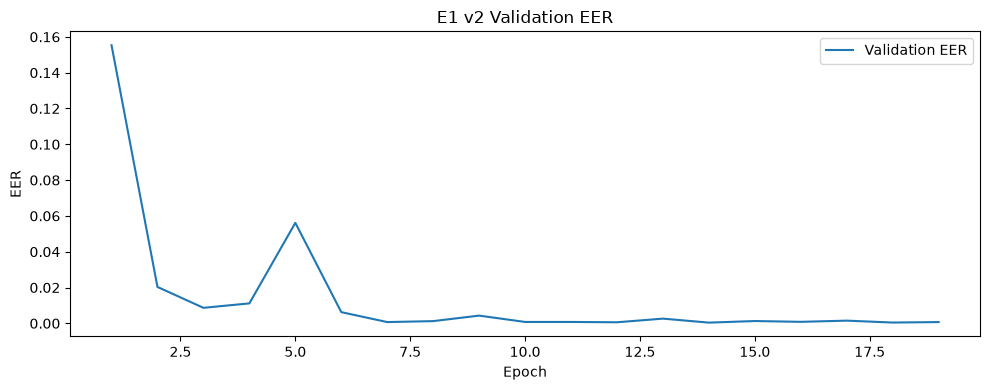

In [19]:
# 18. Plot and save training curves and validation metrics

plt.figure(figsize=(10,4))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train loss"
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("E1 v2 Training and Validation Loss")
plt.legend()
plt.tight_layout()

loss_fig_path=RESULT_FIGURE_DIR/"E1_training_loss_v2.png"
plt.savefig(loss_fig_path,dpi=200)
plt.show()


plt.figure(figsize=(10,4))
plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    label="Train accuracy"
)
plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validation accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("E1 v2 Training and Validation Accuracy")
plt.legend()
plt.tight_layout()

accuracy_fig_path=RESULT_FIGURE_DIR/"E1_training_accuracy_v2.png"
plt.savefig(accuracy_fig_path,dpi=200)
plt.show()


plt.figure(figsize=(10,4))
plt.plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    label="Validation Macro-F1"
)
plt.plot(
    history_df["epoch"],
    history_df["val_auroc"],
    label="Validation AUROC"
)
plt.xlabel("Epoch")
plt.ylabel("Metric")
plt.title("E1 v2 Validation Macro-F1 and AUROC")
plt.legend()
plt.tight_layout()

metric_fig_path=RESULT_FIGURE_DIR/"E1_validation_metrics_v2.png"
plt.savefig(metric_fig_path,dpi=200)
plt.show()


plt.figure(figsize=(10,4))
plt.plot(
    history_df["epoch"],
    history_df["val_eer"],
    label="Validation EER"
)
plt.xlabel("Epoch")
plt.ylabel("EER")
plt.title("E1 v2 Validation EER")
plt.legend()
plt.tight_layout()

eer_fig_path=RESULT_FIGURE_DIR/"E1_validation_eer_v2.png"
plt.savefig(eer_fig_path,dpi=200)
plt.show()


# 14. Final development evaluation

After training, we reload the checkpoint with the best development Macro-F1.

All reported development metrics below therefore correspond to the selected E1 checkpoint rather than simply the final training epoch.


In [20]:
# 19. Load the best E1 checkpoint before final validation

checkpoint=torch.load(best_checkpoint_path,map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])

print("Loaded checkpoint from epoch:",checkpoint["epoch"])
print("Best validation Macro-F1:",checkpoint["best_val_macro_f1"])

Loaded checkpoint from epoch: 14
Best validation Macro-F1: 0.99912567236768


## Development-set results

These are the metrics we use to understand how well the clean E1 baseline learned the bonafide/spoof classification task.

The development predictions are also saved so that later analysis can inspect individual recordings.


In [21]:
# 20. Final development-set evaluation

# Reload the best checkpoint before final development reporting.
if best_checkpoint_path.exists():
    checkpoint=torch.load(
        best_checkpoint_path,
        map_location=DEVICE
    )
    model.load_state_dict(
        checkpoint["model_state_dict"]
    )
    print("Loaded best checkpoint from epoch:",checkpoint["epoch"])

val_metrics,val_y,val_scores,val_preds,val_ids=run_evaluation(
    model,
    dev_loader,
    criterion
)

print("E1 v2 validation results")
print("-"*30)

for key,value in val_metrics.items():
    print(f"{key:<16}: {value:.6f}")

with open(
    EXPERIMENT_DIR/"E1_validation_metrics_v2.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(val_metrics,f,indent=2)


Loaded best checkpoint from epoch: 14


Evaluating:   0%|          | 0/777 [00:00<?, ?it/s]

E1 v2 validation results
------------------------------
macro_f1        : 0.999126
accuracy        : 0.999678
auroc           : 0.999997
eer             : 0.000398
eer_threshold   : 0.947787
loss            : 0.001222


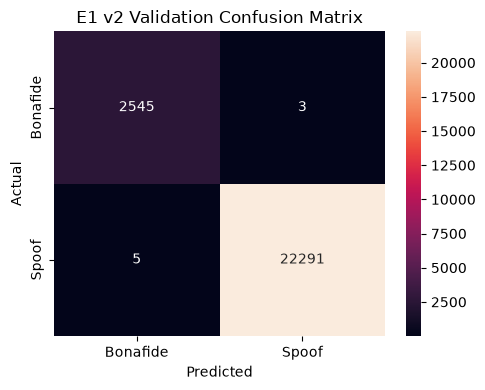

[[ 2545     3]
 [    5 22291]]


In [22]:
# 21. Validation confusion matrix

cm=confusion_matrix(val_y,val_preds)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Bonafide","Spoof"],
    yticklabels=["Bonafide","Spoof"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("E1 v2 Validation Confusion Matrix")
plt.tight_layout()

cm_path=RESULT_FIGURE_DIR/"E1_validation_confusion_matrix_v2.png"
plt.savefig(cm_path,dpi=200)
plt.show()

print(cm)


## Save development predictions

Saving the individual prediction scores is useful later when comparing E1 with E2/E3 or investigating difficult examples.

The file contains the model's spoof score, predicted class and ground-truth label for each development recording.


In [23]:
# 22. Save validation predictions for later analysis

val_predictions_df=pd.DataFrame({
    "file_id":val_ids,
    "label":val_y,
    "spoof_score":val_scores,
    "prediction":val_preds
})

val_predictions_path=EXPERIMENT_DIR/"E1_dev_predictions_v2.csv"
val_predictions_df.to_csv(
    val_predictions_path,
    index=False
)

print("Saved:",val_predictions_path)


Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/ASV_E1_v2/E1_dev_predictions_v2.csv


# 15. Official evaluation inference

The official evaluation partition is processed only after the E1 checkpoint has been selected using the development set.

If evaluation labels are available, the notebook calculates the same metrics used on the development set.

If labels are not available, it saves prediction scores without inventing evaluation metrics.


In [24]:
# 23. Prepare the official evaluation loader

def build_eval_loader(df):
    if len(df)==0:
        return None

    class EvalWaveformDataset(Dataset):
        def __init__(self,df):
            self.df=df.reset_index(drop=True)

        def __len__(self):
            return len(self.df)

        def __getitem__(self,index):
            row=self.df.iloc[index]

            audio_path=PROJECT_ROOT/Path(
                row["audio_path"]
            )

            waveform=load_audio(audio_path)
            waveform=fixed_length_audio(
                waveform,
                training=False
            )

            label=-1 if pd.isna(row["label"]) else int(row["label"])
            y=torch.tensor(
                label,
                dtype=torch.long
            )

            return (
                torch.from_numpy(waveform).float(),
                y,
                row["file_id"]
            )

    dataset=EvalWaveformDataset(df)

    kwargs={
        "batch_size":BATCH_SIZE,
        "shuffle":False,
        "num_workers":NUM_WORKERS,
        "pin_memory":DEVICE.type=="cuda",
        "persistent_workers":NUM_WORKERS>0,
        "worker_init_fn":seed_worker,
        "generator":torch.Generator().manual_seed(SEED)
    }

    if NUM_WORKERS>0:
        kwargs["prefetch_factor"]=PREFETCH_FACTOR

    return DataLoader(
        dataset,
        **kwargs
    )


eval_scores=np.asarray([])
eval_labels=np.asarray([])
eval_ids=[]

eval_loader=build_eval_loader(eval_run_df) if len(eval_run_df) else None

print("Evaluation loader ready:",eval_loader is not None)


Evaluation loader ready: True


In [25]:
# 24. Run official evaluation inference

if len(eval_run_df):
    eval_loader=build_eval_loader(eval_run_df)

    model.eval()

    eval_scores=[]
    eval_labels=[]
    eval_ids=[]

    with torch.no_grad():
        for waveforms,y,file_ids in tqdm(
            eval_loader,
            desc="Official evaluation"
        ):
            x=waveform_batch_to_features(
                waveforms
            )

            logits=model(x)
            scores=torch.softmax(
                logits,
                dim=1
            )[:,1]

            eval_scores.extend(
                scores.cpu().numpy().tolist()
            )
            eval_labels.extend(
                y.numpy().tolist()
            )
            eval_ids.extend(
                list(file_ids)
            )

    eval_scores=np.asarray(eval_scores)
    eval_labels=np.asarray(eval_labels)

    eval_predictions=(eval_scores>=0.5).astype(int)

    eval_output=pd.DataFrame({
        "file_id":eval_ids,
        "spoof_score":eval_scores,
        "prediction":eval_predictions
    })

    eval_output_path=EXPERIMENT_DIR/"E1_eval_predictions_v2.csv"

    eval_output.to_csv(
        eval_output_path,
        index=False
    )

    print("Saved:",eval_output_path)

    if np.all(eval_labels>=0):
        eval_metrics,_=calculate_metrics(
            eval_labels,
            eval_scores
        )

        print("\nOfficial evaluation results")
        print("-"*30)

        for key,value in eval_metrics.items():
            print(f"{key:<16}: {value:.6f}")

        with open(
            EXPERIMENT_DIR/"E1_eval_metrics_v2.json",
            "w",
            encoding="utf-8"
        ) as f:
            json.dump(eval_metrics,f,indent=2)

    else:
        print(
            "\nEvaluation predictions were saved, "
            "but public evaluation labels were not available."
        )

else:
    print("No evaluation manifest was found.")


Official evaluation:   0%|          | 0/2227 [00:00<?, ?it/s]

Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/ASV_E1_v2/E1_eval_predictions_v2.csv

Official evaluation results
------------------------------
macro_f1        : 0.647813
accuracy        : 0.753176
auroc           : 0.932445
eer             : 0.124926
eer_threshold   : 0.000008


Generator/system identity analysis
--------------------------------------------------
Train system IDs: ['-', 'A01', 'A02', 'A03', 'A04', 'A05', 'A06']
Dev system IDs: ['-', 'A01', 'A02', 'A03', 'A04', 'A05', 'A06']
Eval system IDs: ['-', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19']

System IDs shared with train:
['-']

System IDs unseen during training:
['A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19']

System IDs shared with dev:
['-']

Speaker overlap
--------------------------------------------------
Train ∩ Eval: 0
Dev ∩ Eval: 0

Evaluation confusion matrix
--------------------------------------------------
[[ 7345    10]
 [17573 46309]]

Evaluation class-wise metrics
--------------------------------------------------
Bonafide  : F1=0.455179
Spoof     : F1=0.840446

Per-system evaluation results
--------------------------------------------------


,system_id,samples,spoof_detected,spoof_missed,spoof_recall,false_negative_rate,mean_spoof_score
11,A18,4914,21,4893,0.004274,0.995726,0.005262
10,A17,4914,25,4889,0.005088,0.994912,0.005418
8,A15,4914,2480,2434,0.504681,0.495319,0.512430
6,A13,4914,2691,2223,0.547619,0.452381,0.542772
5,A12,4914,3855,1059,0.784493,0.215507,0.774405
3,A10,4914,3903,1011,0.794261,0.205739,0.785148
4,A11,4914,4355,559,0.886243,0.113757,0.878686
7,A14,4914,4426,488,0.900692,0.099308,0.886697
12,A19,4914,4905,9,0.998168,0.001832,0.997419
1,A08,4914,4908,6,0.998779,0.001221,0.998088



Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/ASV_E1_v2/E1_eval_system_results_v2.csv


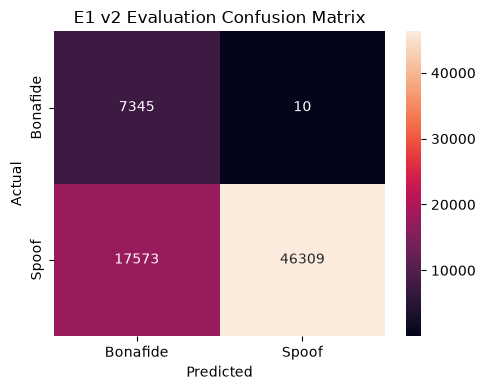

Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/ASV_E1_v2/E1_eval_confusion_matrix_v2.png


In [26]:
# 15.5. Evaluation generalization analysis

if len(eval_run_df) and len(eval_scores):

    eval_analysis=eval_run_df[
        ["file_id","speaker_id","system_id","key","label"]
    ].copy()

    eval_analysis["spoof_score"]=eval_scores
    eval_analysis["prediction"]=(eval_scores>=0.5).astype(int)

    train_systems=set(train_df["system_id"])
    dev_systems=set(dev_df["system_id"])
    eval_systems=set(eval_df["system_id"])

    train_speakers=set(train_df["speaker_id"])
    dev_speakers=set(dev_df["speaker_id"])
    eval_speakers=set(eval_df["speaker_id"])

    print("Generator/system identity analysis")
    print("-"*50)

    print("Train system IDs:",sorted(train_systems))
    print("Dev system IDs:",sorted(dev_systems))
    print("Eval system IDs:",sorted(eval_systems))

    print("\nSystem IDs shared with train:")
    print(sorted(eval_systems&train_systems))

    print("\nSystem IDs unseen during training:")
    print(sorted(eval_systems-train_systems))

    print("\nSystem IDs shared with dev:")
    print(sorted(eval_systems&dev_systems))

    print("\nSpeaker overlap")
    print("-"*50)

    print("Train ∩ Eval:",len(train_speakers&eval_speakers))
    print("Dev ∩ Eval:",len(dev_speakers&eval_speakers))

    eval_cm=confusion_matrix(
        eval_labels,
        eval_analysis["prediction"].to_numpy()
    )

    print("\nEvaluation confusion matrix")
    print("-"*50)
    print(eval_cm)

    print("\nEvaluation class-wise metrics")
    print("-"*50)

    class_names=["Bonafide","Spoof"]

    for class_index,class_name in enumerate(class_names):

        class_true=(eval_labels==class_index).astype(int)
        class_pred=(
            eval_analysis["prediction"].to_numpy()==class_index
        ).astype(int)

        class_f1=f1_score(
            class_true,
            class_pred
        )

        print(
            f"{class_name:<10}: "
            f"F1={class_f1:.6f}"
        )

    print("\nPer-system evaluation results")
    print("-"*50)

    system_results=[]

    for system_id,group in eval_analysis.groupby("system_id"):

        if system_id=="-":
            continue

        y_true=group["label"].to_numpy()
        predictions=group["prediction"].to_numpy()
        scores=group["spoof_score"].to_numpy()

        spoof_count=(y_true==1).sum()
        detected_spoof=((y_true==1)&(predictions==1)).sum()
        missed_spoof=((y_true==1)&(predictions==0)).sum()

        spoof_recall=(
            detected_spoof/spoof_count
            if spoof_count>0
            else np.nan
        )

        false_negative_rate=(
            missed_spoof/spoof_count
            if spoof_count>0
            else np.nan
        )

        system_results.append({
            "system_id":system_id,
            "samples":len(group),
            "spoof_detected":detected_spoof,
            "spoof_missed":missed_spoof,
            "spoof_recall":spoof_recall,
            "false_negative_rate":false_negative_rate,
            "mean_spoof_score":scores.mean()
        })

    system_results_df=pd.DataFrame(system_results)

    if len(system_results_df):

        system_results_df=system_results_df.sort_values(
            "spoof_recall"
        )

        display(system_results_df)

        system_results_path=(
            EXPERIMENT_DIR/"E1_eval_system_results_v2.csv"
        )

        system_results_df.to_csv(
            system_results_path,
            index=False
        )

        print("\nSaved:",system_results_path)

    else:
        print("No spoof system results were found.")

    eval_cm_path=(
        RESULT_FIGURE_DIR/
        "E1_eval_confusion_matrix_v2.png"
    )

    plt.figure(figsize=(5,4))

    sns.heatmap(
        eval_cm,
        annot=True,
        fmt="d",
        xticklabels=["Bonafide","Spoof"],
        yticklabels=["Bonafide","Spoof"]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("E1 v2 Evaluation Confusion Matrix")
    plt.tight_layout()
    plt.savefig(eval_cm_path,dpi=200)
    plt.show()

    print("Saved:",eval_cm_path)

else:
    print("Evaluation results are not available.")

## ASVspoof 2019 LA System IDs

The `system_id` field identifies the spoofing/attack system that generated
a spoofed utterance in the ASVspoof 2019 Logical Access (LA) dataset.

The training and development partitions contain systems A01-A06.
The evaluation partition contains A07-A19, with A16 and A19 using the
same core algorithms as A04 and A06 respectively, but generated using
the evaluation-set data.

### Training and Development Systems

| System ID | Type | Description |
|---|---|---|
| A01 | TTS | Neural statistical parametric TTS using a WaveNet neural vocoder. |
| A02 | TTS | Neural TTS similar to A01, but using the WORLD vocoder instead of WaveNet. |
| A03 | TTS | Neural TTS based on the Merlin toolkit, using feed-forward neural networks and the WORLD vocoder. |
| A04 | TTS | Waveform-concatenation TTS based on MaryTTS and diphone unit selection. |
| A05 | VC | VAE-based non-parallel voice conversion using the WORLD vocoder. |
| A06 | VC | Transfer-function-based voice conversion using GMM-UBM modeling and spectral filtering/overlap-add. |

### Evaluation Systems

| System ID | Type | Description |
|---|---|---|
| A07 | TTS | Neural TTS using a WORLD vocoder followed by a WaveCycleGAN2 neural post-filter. |
| A08 | TTS | Neural TTS similar to A01, using a neural source-filter waveform model. |
| A09 | TTS | Neural statistical parametric TTS designed for real-time/mobile use, using LSTM models and the Vocaine vocoder. |
| A10 | TTS | End-to-end Tacotron 2 based TTS with a speaker encoder and WaveRNN vocoder. |
| A11 | TTS | Same general TTS architecture as A10, but uses Griffin-Lim instead of WaveRNN for waveform generation. |
| A12 | TTS | Neural TTS using an autoregressive WaveNet waveform generator. |
| A13 | VC + TTS | Combined TTS and voice-conversion system using VoiceText TTS followed by neural VC and waveform modification. |
| A14 | VC + TTS | Combined TTS and VC system using a commercial TTS engine, ASR bottleneck features, an LSTM acoustic model and STRAIGHT vocoder. |
| A15 | VC + TTS | Similar to A14, but uses speaker-dependent WaveNet vocoders instead of STRAIGHT. |
| A16 | TTS | Waveform-concatenation TTS using the same core algorithm as A04, but constructed using evaluation-set VCTK data. |
| A17 | VC | VAE-based voice conversion similar to A05, but using generalized direct waveform modification instead of the WORLD vocoder. |
| A18 | VC | Non-parallel voice conversion based on an i-vector/PLDA framework with an MFCC-based vocoder. |
| A19 | VC | Transfer-function-based voice conversion using the same core algorithm as A06, but constructed using evaluation-set VCTK data. |

### Important Generalization Groups

For this experiment, the system IDs are especially important because they
help distinguish between familiar and unseen spoofing mechanisms.

- **A01-A06:** spoofing systems present in training/development.
- **A07-A15:** evaluation systems with spoofing mechanisms not directly
  represented by A01-A06.
- **A16:** evaluation system using the same core algorithm as A04.
- **A17-A18:** different voice-conversion systems using mechanisms not
  directly represented by the training systems.
- **A19:** evaluation system using the same core algorithm as A06.

Therefore, evaluation performance on A07-A19 provides a useful test of
generalization beyond the spoofing systems observed during training.

For our E1 experiment, `system_id="-"` represents bona-fide recordings,
which do not have a spoofing-system identifier.

**Source:** Wang et al., *ASVspoof 2019: A large-scale public database of
synthesized, converted and replayed speech*.

In [27]:
# Evaluation failure-case analysis

if len(eval_analysis):

    false_negatives=eval_analysis[
        (eval_analysis["label"]==1)&
        (eval_analysis["prediction"]==0)
    ].copy()

    false_positives=eval_analysis[
        (eval_analysis["label"]==0)&
        (eval_analysis["prediction"]==1)
    ].copy()

    false_negatives=false_negatives.sort_values(
        "spoof_score"
    )

    false_positives=false_positives.sort_values(
        "spoof_score",
        ascending=False
    )

    print("Evaluation failure-case analysis")
    print("-"*50)

    print(
        "\nFalse-negative spoof samples:",
        len(false_negatives)
    )

    print(
        "False-positive bonafide samples:",
        len(false_positives)
    )

    print("\nMost confidently missed spoof samples")
    print("-"*50)

    display(
        false_negatives[
            [
                "file_id",
                "speaker_id",
                "system_id",
                "spoof_score"
            ]
        ].head(25)
    )

    print("\nMost confidently misclassified bonafide samples")
    print("-"*50)

    display(
        false_positives[
            [
                "file_id",
                "speaker_id",
                "system_id",
                "spoof_score"
            ]
        ].head(25)
    )

    failure_cases=pd.concat(
        [
            false_negatives.head(25).assign(
                error_type="false_negative"
            ),
            false_positives.head(25).assign(
                error_type="false_positive"
            )
        ]
    )

    failure_cases_path=(
        EXPERIMENT_DIR/
        "E1_eval_failure_cases_v2.csv"
    )

    failure_cases.to_csv(
        failure_cases_path,
        index=False
    )

    print("\nSaved:",failure_cases_path)

else:
    print("Evaluation analysis is not available.")

Evaluation failure-case analysis
--------------------------------------------------

False-negative spoof samples: 17573
False-positive bonafide samples: 10

Most confidently missed spoof samples
--------------------------------------------------


,file_id,speaker_id,system_id,spoof_score
3117,LA_E_6124076,LA_0006,A17,2.796256e-13
23599,LA_E_7119151,LA_0042,A17,4.211961e-13
21151,LA_E_2845798,LA_0036,A17,4.127472e-12
61936,LA_E_3039325,LA_0026,A17,7.151724e-12
32215,LA_E_9566831,LA_0027,A17,1.089510e-11
3425,LA_E_1907790,LA_0008,A17,1.094490e-11
45032,LA_E_7790084,LA_0047,A17,1.113122e-11
50125,LA_E_8535825,LA_0031,A17,1.440338e-11
42800,LA_E_8128329,LA_0047,A17,1.722262e-11
1579,LA_E_6104183,LA_0027,A17,2.319653e-11



Most confidently misclassified bonafide samples
--------------------------------------------------


,file_id,speaker_id,system_id,spoof_score
5527,LA_E_3233085,LA_0059,-,0.999999
23641,LA_E_8509707,LA_0059,-,0.999974
44107,LA_E_6372044,LA_0036,-,0.999921
63560,LA_E_2782166,LA_0067,-,0.999368
62761,LA_E_1450790,LA_0057,-,0.997978
36686,LA_E_3462351,LA_0057,-,0.993273
23298,LA_E_1553940,LA_0054,-,0.977502
2110,LA_E_6592171,LA_0033,-,0.957615
25826,LA_E_4228891,LA_0060,-,0.658132
30327,LA_E_2198141,LA_0052,-,0.523500



Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/ASV_E1_v2/E1_eval_failure_cases_v2.csv


# 16. Save the E1 experiment configuration

The final configuration records the model, preprocessing, dataset preparation version and training settings.

This is important because later changes to preprocessing or model design should produce a new experiment version rather than silently changing the meaning of E1.


In [28]:
# 25. Save the complete E1 v2 configuration

config={
    "experiment":"E1",
    "experiment_version":EXPERIMENT_VERSION,
    "input_preprocessing_version":INPUT_PREPROCESSING_VERSION,
    "dataset_preparation_version":"v1.0",

    "model":{
        "name":"MobileNetV3-Small",
        "weights":"scratch",
        "input_channels":1,
        "num_classes":2,
        "total_parameters":total_params,
        "trainable_parameters":trainable_params
    },

    "dataset":{
        "name":"ASVspoof 2019 Logical Access",
        "train_manifest":"data/manifests/ASVSpoof/train_manifest.csv",
        "dev_manifest":"data/manifests/ASVSpoof/dev_manifest.csv",
        "eval_manifest":"data/manifests/ASVSpoof/eval_manifest.csv",
        "train_samples":len(train_run_df),
        "dev_samples":len(dev_run_df),
        "eval_samples":len(eval_run_df)
    },

    "audio":{
        "sample_rate":SAMPLE_RATE,
        "segment_seconds":SEGMENT_SECONDS,
        "num_samples":NUM_SAMPLES
    },

    "spectrogram":{
        "n_fft":N_FFT,
        "win_length":WIN_LENGTH,
        "hop_length":HOP_LENGTH,
        "n_mels":N_MELS,
        "window":"hann",
        "power":2.0,
        "log_epsilon":LOG_EPS
    },

    "training_preprocessing":{
        "train_crop":"random",
        "eval_crop":"center",
        "short_audio":"zero_pad",
        "normalization":"training_set_mean_std",
        "feature_pipeline":"batched_gpu_logmel"
    },

    "training":{
        "seed":SEED,
        "batch_size":BATCH_SIZE,
        "epochs":EPOCHS,
        "learning_rate":LEARNING_RATE,
        "weight_decay":WEIGHT_DECAY,
        "patience":PATIENCE,
        "loss":"class_weighted_cross_entropy",
        "optimizer":"AdamW",
        "num_workers":NUM_WORKERS,
        "prefetch_factor":PREFETCH_FACTOR,
        "cudnn_deterministic":(
            torch.backends.cudnn.deterministic
            if DEVICE.type=="cuda"
            else None
        ),
        "cudnn_benchmark":(
            torch.backends.cudnn.benchmark
            if DEVICE.type=="cuda"
            else None
        )
    },

    "excluded_from_E1":[
        "environmental_noise",
        "codec_simulation",
        "telephony_filtering",
        "SpecAugment",
        "robustness_consistency_loss",
        "knowledge_distillation",
        "pruning",
        "quantization",
        "edge_benchmarking"
    ]
}

config_path=EXPERIMENT_DIR/"E1_config_v2.json"

with config_path.open("w",encoding="utf-8") as f:
    json.dump(config,f,indent=2)

print("Saved configuration:",config_path)


Saved configuration: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/baselines/ASV_E1_v2/E1_config_v2.json


# E1 v2 Final Observations

## Model

E1 v2 uses a scratch-trained MobileNetV3-Small audio classifier operating on
80-bin log-Mel spectrograms generated from a **24 kHz** waveform frontend.

## Pipeline

The experiment uses the optimized batched feature pipeline:

```text
Audio → mono/resample → fixed 4 s crop/zero-padding
     → waveform batch → GPU STFT → Mel → log
     → training-set normalization → MobileNetV3-Small
```

The expensive Log-Mel computation is therefore not performed separately inside
`Dataset.__getitem__()` for every sample.

## Optimization

E1 v2 uses class-weighted cross entropy with AdamW optimization. A `ReduceLROnPlateau` scheduler monitors development Macro-F1 and reduces the learning rate when the metric plateaus.

## Metrics

The notebook records, for every epoch:

- Train loss
- Train accuracy
- Validation loss
- Validation accuracy
- Validation Macro-F1
- Validation AUROC
- Validation EER
- Learning rate
- Epoch time

The final development metrics are saved to `E1_validation_metrics_v2.json`.

## Experimental boundary

E1 v2 changes the E1 input frontend from 16 kHz to 24 kHz and updates the
implementation to the batched GPU Log-Mel pipeline. The detector remains the
same MobileNetV3-Small baseline. No GRU/LSTM or robustness/compression method
is included.

The best checkpoint is selected using development Macro-F1. The official
evaluation partition is not used for model selection.

**Do not enter numerical observations here before the notebook has been run.**
The cells above generate the actual values for the experiment record.


# 17. E1 v2 outputs and experiment record

After a successful run, E1 v2 should leave behind:

1. **Configuration** - exactly how E1 v2 was run.
2. **Checkpoint** - the selected MobileNetV3-Small model.
3. **Quantitative results** - loss, accuracy, Macro-F1, AUROC, EER and EER threshold.
4. **Analysis artifacts** - predictions, training curves, confusion matrices, system-level results and failure cases.

These artifacts allow E1 v2 to serve as the 24 kHz optimized implementation baseline for later experiments.

The outputs are stored under the dedicated `ASV_E1_v2` experiment directories.


In [29]:
# E1 v2 experiment artifact audit

required_artifacts={
    "Best checkpoint":
        CHECKPOINT_DIR/"E1_MobileNetV3Small_v2_best.pt",

    "Validation metrics":
        EXPERIMENT_DIR/"E1_validation_metrics_v2.json",

    "Training history":
        EXPERIMENT_DIR/"training_history.csv",

    "Log-Mel normalization statistics":
        EXPERIMENT_DIR/"logmel_stats.json",

    "Development predictions":
        EXPERIMENT_DIR/"E1_dev_predictions_v2.csv",

    "System generalization results":
        EXPERIMENT_DIR/"E1_eval_system_results_v2.csv",

    "Failure-case results":
        EXPERIMENT_DIR/"E1_eval_failure_cases_v2.csv",

    "Validation confusion matrix":
        RESULT_FIGURE_DIR/"E1_validation_confusion_matrix_v2.png",

    "Evaluation confusion matrix":
        RESULT_FIGURE_DIR/"E1_eval_confusion_matrix_v2.png",

    "Training loss figure":
        RESULT_FIGURE_DIR/"E1_training_loss_v2.png",

    "Training accuracy figure":
        RESULT_FIGURE_DIR/"E1_training_accuracy_v2.png",

    "Validation metrics figure":
        RESULT_FIGURE_DIR/"E1_validation_metrics_v2.png",

    "Validation EER figure":
        RESULT_FIGURE_DIR/"E1_validation_eer_v2.png"
}

print("E1 v2 experiment artifact audit")
print("-"*50)

all_available=True

for name,path in required_artifacts.items():
    status="OK" if path.exists() else "MISSING"
    print(f"{name:<35}: {status}")

    if not path.exists():
        all_available=False

print("-"*50)

if all_available:
    print("All required E1 v2 artifacts are available.")
else:
    print("Some E1 v2 artifacts are missing. This is expected before the full run.")


E1 v2 experiment artifact audit
--------------------------------------------------
Best checkpoint                    : OK
Validation metrics                 : OK
Training history                   : OK
Log-Mel normalization statistics   : OK
Development predictions            : OK
System generalization results      : OK
Failure-case results               : OK
Validation confusion matrix        : OK
Evaluation confusion matrix        : OK
Training loss figure               : OK
Training accuracy figure           : OK
Validation metrics figure          : OK
Validation EER figure              : OK
--------------------------------------------------
All required E1 v2 artifacts are available.
